# MATH840 final project: EDA and a model tournament

Everything here is **experiments**: no submission is written. The plan is EDA, then a rolling-origin
backtest of many forecasters on the same 48-hour task, then prediction intervals for the best few. We
choose the final model after reading the results.

Files needed next to the notebook (upload them in Colab when asked): `train.csv`, `weather_forecast.csv`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 150, "display.max_columns", 40, "display.precision", 3)

NEEDED = ["train.csv", "weather_forecast.csv"]
if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

try:
    import lightgbm as lgb
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], check=True)
    import lightgbm as lgb

data = pd.read_csv("train.csv", parse_dates=["ds"])
wfc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48
WX = ["cloud_cover", "temperature", "wind_speed", "pressure", "humidity", "daylight", "air_density"]
WEATHER6 = [c for c in WX if c != "daylight"]          # daylight is a calendar fact, the rest is weather
assert len(wfc) == H and wfc["ds"].iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"forecast: {wfc['ds'].iloc[0]} to {wfc['ds'].iloc[-1]}")

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
forecast: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


In [2]:
# The three scores and the benchmark, exactly as in the course template.
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def snaive(history, h: int = H, m: int = 24):
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

## 1. EDA

Questions to answer from the plots: how does the level change over time, what is the daily shape, how
much does the weather explain, and does the forecast weather look like the weather the model was trained on.

In [3]:
# 1.1 Data quality
full = pd.date_range(data["ds"].min(), data["ds"].max(), freq="h")
print("missing hours:", len(full) - data["ds"].nunique(), "| duplicates:", int(data["ds"].duplicated().sum()),
      "| nulls:", int(data.isna().sum().sum()))
print(data[["y"] + WX].describe().T[["mean", "std", "min", "50%", "max"]])
print("hours with y < 5:", int((data["y"] < 5).sum()), "of", len(data), " -> MAPE is very sensitive to these hours")

missing hours: 0 | duplicates: 0 | nulls: 0
                mean      std      min      50%      max
y            315.755  377.596    0.700  220.600  3111.30
cloud_cover    0.603    0.418    0.000    0.750     1.00
temperature   12.225   10.664  -19.000   12.000    39.00
wind_speed     3.727    2.326    0.000    3.000    14.00
pressure     757.662    5.537  736.000  757.000   775.00
humidity      71.699   21.176    7.000   77.000   100.00
daylight       0.475    0.499    0.000    0.000     1.00
air_density    1.238    0.050    1.124    1.235     1.41
hours with y < 5: 398 of 33480  -> MAPE is very sensitive to these hours


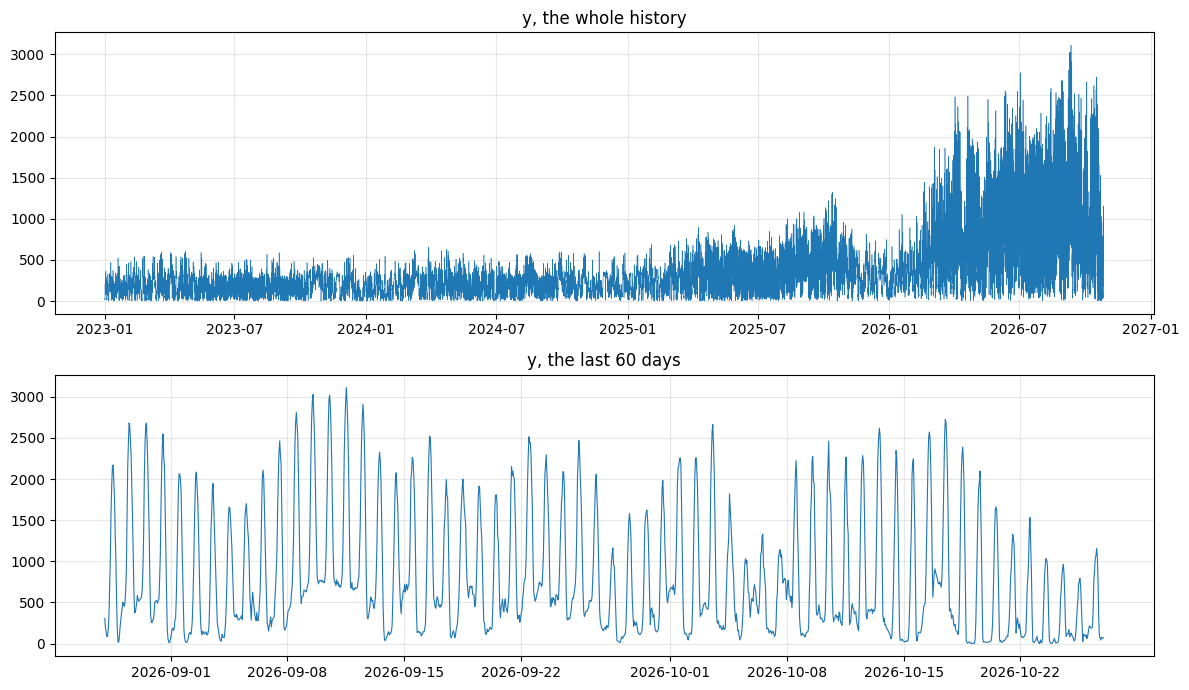

In [4]:
# 1.2 The series, in full and over the last 60 days
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(data["ds"], data["y"], lw=0.4)
axes[0].set_title("y, the whole history")
last = data[data["ds"] > data["ds"].max() - pd.Timedelta(days=60)]
axes[1].plot(last["ds"], last["y"], lw=0.8)
axes[1].set_title("y, the last 60 days")
plt.tight_layout(); plt.show()

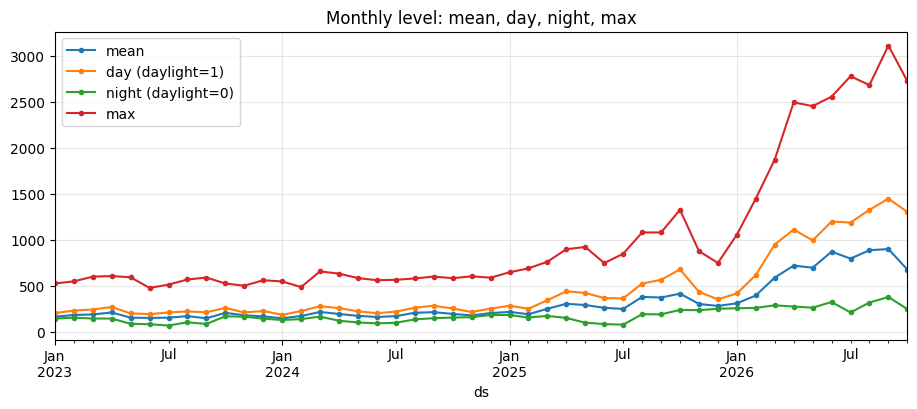

       mean    std     max
ds                        
2023  171.0  123.0   604.0
2024  184.0  127.0   655.0
2025  291.0  220.0  1325.0
2026  684.0  620.0  3111.0


In [5]:
# 1.3 The level changes: monthly mean, and the daytime / night-time split
d = data.set_index("ds")
monthly = pd.DataFrame({
    "mean": d["y"].resample("MS").mean(),
    "day (daylight=1)": d[d["daylight"] == 1]["y"].resample("MS").mean(),
    "night (daylight=0)": d[d["daylight"] == 0]["y"].resample("MS").mean(),
    "max": d["y"].resample("MS").max(),
})
ax = monthly.plot(figsize=(11, 4), marker="o", ms=3)
ax.set_title("Monthly level: mean, day, night, max")
plt.show()
print(d["y"].groupby(d.index.year).agg(["mean", "std", "max"]).round(0))

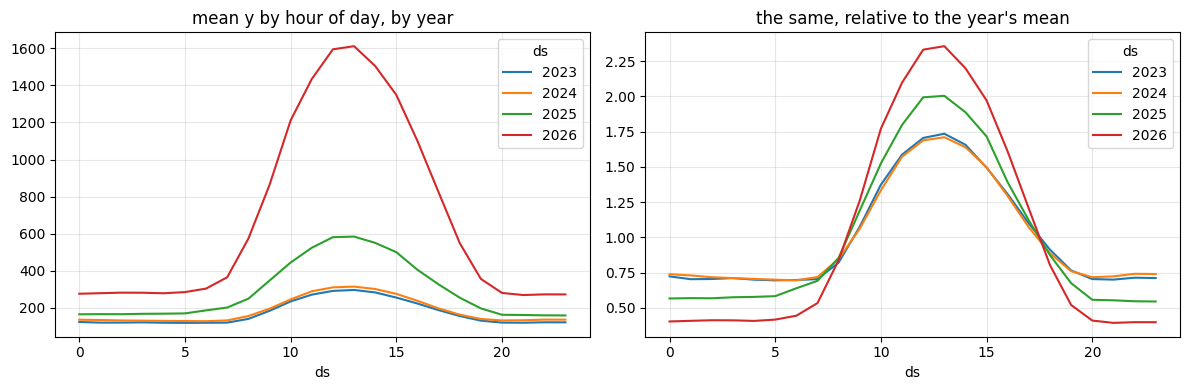

In [6]:
# 1.4 The daily shape, by year (absolute, then relative to each year's mean)
prof = d.groupby([d.index.year, d.index.hour])["y"].mean().unstack(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
prof.plot(ax=axes[0]); axes[0].set_title("mean y by hour of day, by year")
(prof / prof.mean()).plot(ax=axes[1]); axes[1].set_title("the same, relative to the year's mean")
plt.tight_layout(); plt.show()

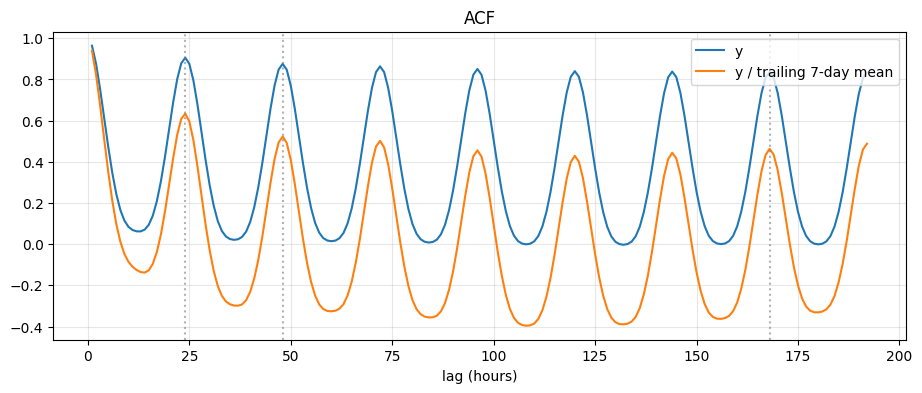

In [7]:
# 1.5 Autocorrelation, raw and after removing the slow level (y divided by its trailing 7-day mean)
y_s = data["y"]
rel = y_s / y_s.rolling(168).mean().shift(1)
lags = np.arange(1, 24 * 8 + 1)
acf_raw = [y_s.autocorr(int(l)) for l in lags]
acf_rel = [rel.autocorr(int(l)) for l in lags]
fig, ax = plt.subplots()
ax.plot(lags, acf_raw, label="y"); ax.plot(lags, acf_rel, label="y / trailing 7-day mean")
for l in (24, 48, 168): ax.axvline(l, color="gray", ls=":", alpha=0.6)
ax.set_xlabel("lag (hours)"); ax.legend(); ax.set_title("ACF")
plt.show()

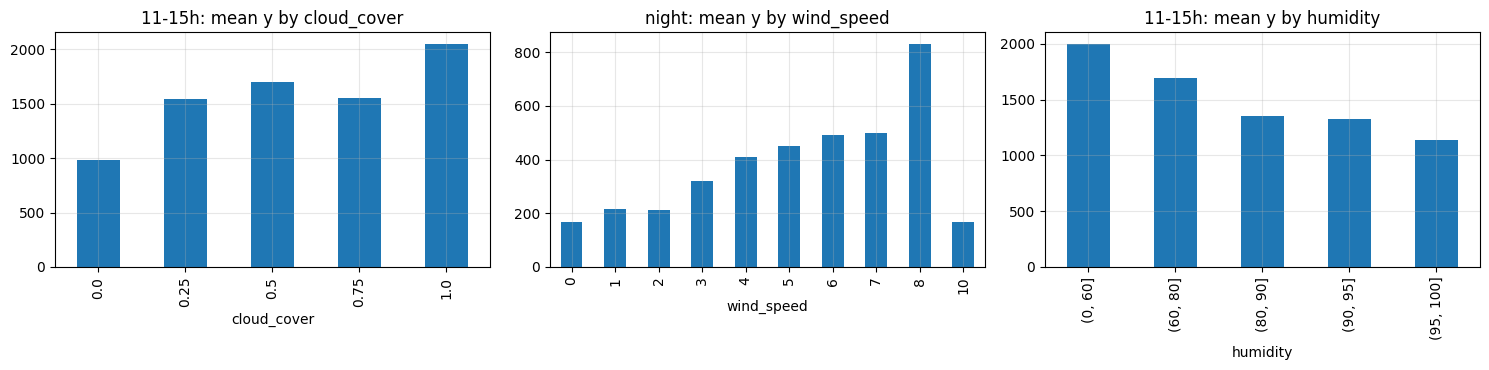

correlation with y, daytime:
 {'cloud_cover': 0.17, 'temperature': 0.43, 'wind_speed': 0.35, 'pressure': 0.19, 'humidity': -0.57, 'air_density': -0.36}
correlation with y, night:
 {'cloud_cover': 0.26, 'temperature': 0.02, 'wind_speed': 0.42, 'pressure': 0.09, 'humidity': -0.26, 'air_density': 0.0}


In [8]:
# 1.6 How the weather relates to y (last 120 days, to stay near the current level)
recent = data[data["ds"] > data["ds"].max() - pd.Timedelta(days=120)].copy()
recent["hour"] = recent["ds"].dt.hour
dayh = recent[(recent["hour"] >= 11) & (recent["hour"] <= 15)]
night_ = recent[recent["daylight"] == 0]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
dayh.groupby("cloud_cover")["y"].mean().plot.bar(ax=axes[0], title="11-15h: mean y by cloud_cover")
night_.groupby("wind_speed")["y"].mean().plot.bar(ax=axes[1], title="night: mean y by wind_speed")
dayh.groupby(pd.cut(dayh["humidity"], [0, 60, 80, 90, 95, 100]))["y"].mean().plot.bar(ax=axes[2], title="11-15h: mean y by humidity")
plt.tight_layout(); plt.show()
cols = ["y"] + WEATHER6
print("correlation with y, daytime:\n", recent[recent["daylight"] == 1][cols].corr()["y"].drop("y").round(2).to_dict())
print("correlation with y, night:\n", recent[recent["daylight"] == 0][cols].corr()["y"].drop("y").round(2).to_dict())

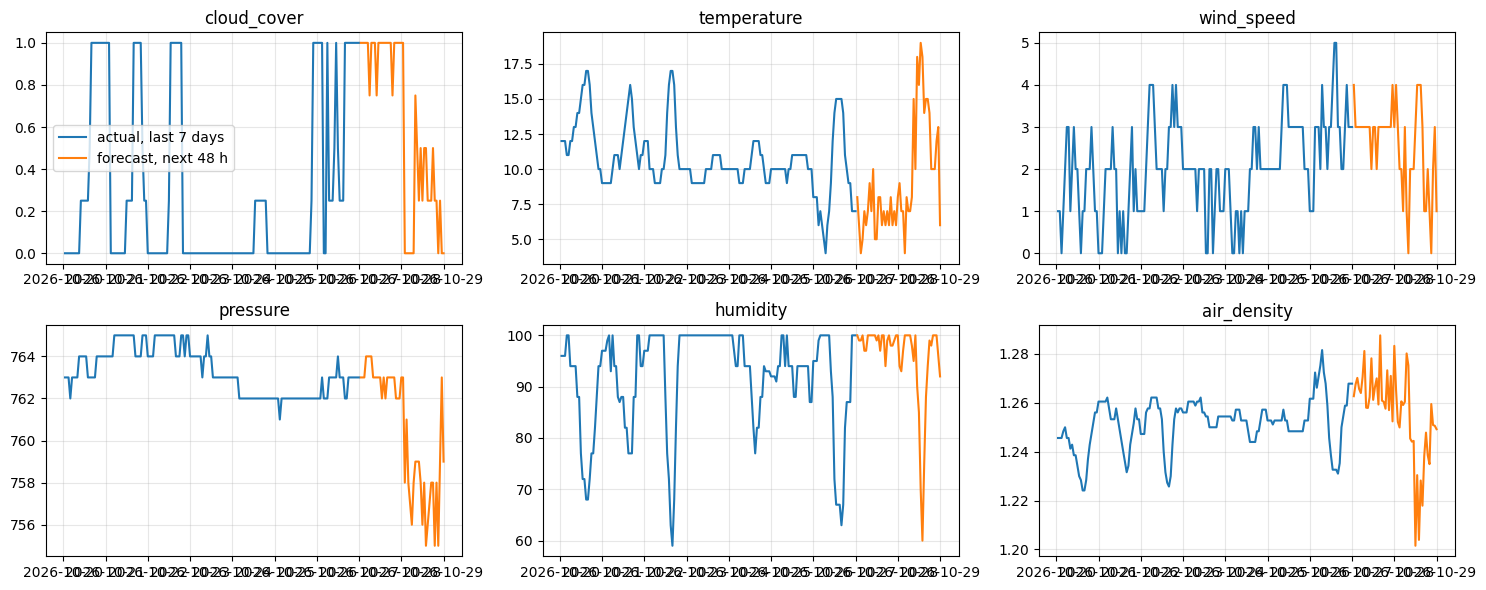

            forecast file                      last 30 days                      
                     mean   std    min     max         mean    std     min    max
cloud_cover          0.61  0.41    0.0    1.00         0.58   0.44    0.00    1.0
temperature          9.04  3.90    4.0   19.00        12.81   4.47   -1.00   25.0
wind_speed           2.56  1.01    0.0    4.00         2.93   1.88    0.00   10.0
pressure           760.50  2.93  755.0  764.00       759.52   4.54  748.00  766.0
humidity            95.83  8.10   60.0  100.00        83.56  16.73   31.00  100.0
air_density          1.26  0.02    1.2    1.29         1.24   0.02    1.17    1.3


In [9]:
# 1.7 The forecast weather for the 48 hours, next to the last 7 days of actual weather
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
last7 = data[data["ds"] > data["ds"].max() - pd.Timedelta(days=7)]
for ax, c in zip(axes.ravel(), WEATHER6):
    ax.plot(last7["ds"], last7[c], label="actual, last 7 days")
    ax.plot(wfc["ds"], wfc[c], label="forecast, next 48 h")
    ax.set_title(c)
axes[0, 0].legend()
plt.tight_layout(); plt.show()
print(pd.concat({"forecast file": wfc[WEATHER6].describe().loc[["mean", "std", "min", "max"]].T,
                 "last 30 days": data.tail(720)[WEATHER6].describe().loc[["mean", "std", "min", "max"]].T}, axis=1).round(2))

In [10]:
# 1.8 Does cloud_cover mean the same thing in train.csv and in weather_forecast.csv?
mid = data[(data["ds"].dt.hour.between(10, 15)) & (data["ds"] >= data["ds"].max() - pd.Timedelta(days=90))]
print("TRAIN, midday (10-15h), last 90 days: humidity, temperature and y by cloud_cover")
display(mid.groupby("cloud_cover").agg(humidity=("humidity", "mean"), temperature=("temperature", "mean"),
                                       y=("y", "mean"), hours=("y", "size")).round(1))
fm = wfc[wfc["ds"].dt.hour.between(10, 15)]
print("FORECAST FILE, midday (10-15h): humidity and temperature by cloud_cover")
display(fm.groupby("cloud_cover").agg(humidity=("humidity", "mean"), temperature=("temperature", "mean"),
                                      hours=("temperature", "size")).round(1))

def daily(df, with_y):
    g = df.groupby(df["ds"].dt.date)
    out = pd.DataFrame({"cloud_cover": g["cloud_cover"].mean(), "humidity": g["humidity"].mean(),
                        "temp range": g["temperature"].agg(lambda s: s.max() - s.min())})
    if with_y:
        out["y peak"], out["y mean"] = g["y"].max(), g["y"].mean()
    return out.round(2)

print("the last 9 days of train.csv, daily:")
display(daily(data[data["ds"] >= data["ds"].max() - pd.Timedelta(days=9)], True))
print("the forecast file, daily:")
display(daily(wfc, False))

TRAIN, midday (10-15h), last 90 days: humidity, temperature and y by cloud_cover


,humidity,temperature,y,hours
cloud_cover,,,,
0.00,95.6,11.1,950.1,25
0.25,74.2,16.6,1454.9,101
0.50,64.6,18.4,1564.0,33
0.75,43.0,32.0,1575.5,1
1.00,41.1,25.2,2019.9,380


FORECAST FILE, midday (10-15h): humidity and temperature by cloud_cover


,humidity,temperature,hours
cloud_cover,,,
0.25,86.7,13.3,3
0.50,73.3,18.3,3
0.75,100.0,10.0,1
1.00,99.2,6.4,5


the last 9 days of train.csv, daily:


,cloud_cover,humidity,temp range,y peak,y mean
ds,,,,,
2026-10-18,0.69,83.38,14,2387.9,713.89
2026-10-19,0.15,94.50,2,2097.5,559.55
2026-10-20,0.41,86.54,7,1661.8,473.04
2026-10-21,0.42,90.88,7,1330.3,450.62
2026-10-22,0.30,91.42,8,1531.7,391.71
2026-10-23,0.00,100.00,2,1033.0,289.25
2026-10-24,0.07,92.54,3,960.4,285.99
2026-10-25,0.09,93.29,2,793.2,257.62
2026-10-26,0.69,87.96,11,1156.3,390.05


the forecast file, daily:


,cloud_cover,humidity,temp range
ds,,,
2026-10-27,0.97,98.96,6
2026-10-28,0.30,93.00,15
2026-10-29,0.00,92.00,0


**cloud_cover: a check before any weather model is trusted.** In `train.csv`, `cloud_cover = 1.0` goes with dry,
warm, high-output hours, so it behaves like **clear sky**. In `weather_forecast.csv`, `1.0` goes with about 99% humidity
and a small temperature swing (the dull Oct 27), which is **overcast** by the training data's own logic. If the two
files really use opposite conventions, a model that uses `cloud_cover` will read the forecast the wrong way round. The
variables that agree between the files (humidity, temperature, wind, pressure) are safe. The tournament therefore has
`(no cloud)` variants, and the final choice should not depend on `cloud_cover` unless this is resolved.

**Your reading.** Write down what you see in 1.2 to 1.8 before moving on (level changes, daily shape, which weather
variables matter day and night, anything odd).

→

## 2. The backtest

The real task: at midnight, forecast the next 48 hours given everything up to then and a weather forecast.
The backtest repeats that on the **last 60 midnights** of the history (each origin forecasts its own next 48
hours). Models that learn are refit every 10 origins on data that was known at that moment.

Two weather settings are run for every model: the **actual** weather (optimistic) and **noisy** weather,
which mimics a forecast whose errors grow over the horizon. The noise sizes are assumptions, since we have no
history of past forecasts: they are chosen to look like a service that is right about the cloud cover most of
the time on day 1 and less on day 2.

In [11]:
y = data["y"].to_numpy(float)
n = len(y)
ds = data["ds"]
hour = ds.dt.hour.to_numpy()
W = {c: data[c].to_numpy(float) for c in WX}
K = np.arange(1, H + 1)

s_ = pd.Series(y)
LEVEL = {w: s_.rolling(w).mean().to_numpy() for w in (24, 72, 168, 336)}
PEAK168 = s_.rolling(168).max().to_numpy()
night = 1.0 - W["daylight"]
NIGHT168 = (pd.Series(y * night).rolling(168).sum() / pd.Series(night).rolling(168).sum()).to_numpy()
L = LEVEL[168]                                              # the 'level' used to scale ratio models

# origins: every midnight with a full history behind it and 48 known hours after it
idx_all = np.arange(n)
ORIG_ALL = np.where((hour == 0) & (idx_all >= 720) & (idx_all + H <= n - 1))[0]
NVAL, BLOCK = 60, 10
VAL = ORIG_ALL[-NVAL:]
print("training origins available:", len(ORIG_ALL), "| validation origins:", len(VAL),
      "from", ds.iloc[VAL[0]].date(), "to", ds.iloc[VAL[-1]].date())


def hist_wx(orig):
    orig = np.asarray(orig)
    return {c: W[c][orig[:, None] + K[None, :]] for c in WX}


def perturb(wx, rng):
    # Simulated weather-forecast error, growing with the horizon (an assumption, see the text above).
    g = (K / H)[None, :]
    out = {c: v.copy() for c, v in wx.items()}
    shape = wx["cloud_cover"].shape
    out["cloud_cover"] = np.clip(np.round((wx["cloud_cover"] + rng.normal(0, 0.15 + 0.25 * g, shape)) * 4) / 4, 0, 1)
    out["temperature"] = wx["temperature"] + rng.normal(0, 1.0 + 1.5 * g, shape)
    out["wind_speed"] = np.clip(wx["wind_speed"] + rng.normal(0, 0.5 + 0.7 * g, shape), 0, None)
    out["pressure"] = wx["pressure"] + rng.normal(0, 1.0 + 2.0 * g, shape)
    out["humidity"] = np.clip(wx["humidity"] + rng.normal(0, 4 + 6 * g, shape), 0, 100)
    out["air_density"] = wx["air_density"] + rng.normal(0, 0.005 + 0.007 * g, shape)
    return out

training origins available: 1363 | validation origins: 60 from 2026-08-27 to 2026-10-25


In [12]:
LEVEL_COLS = ["same1", "same3", "same7", "same7med", "same7max", "lvl24", "lvl72", "lvl336", "peak168", "night168", "last"]


def same_hour(orig, days):
    # y at the same hour of day, 1, 2, ... `days` days back from the target hour, using only data up to the origin.
    m0 = np.ceil(K / 24).astype(int)
    pos = np.asarray(orig)[:, None, None] + K[None, :, None] - 24 * (m0[None, :, None] + np.arange(days)[None, None, :])
    return y[pos]


def make_features(orig, wx):
    orig = np.asarray(orig); no = len(orig)
    f = {"k": np.tile(K, no)}
    f["hour"] = ((hour[orig][:, None] + K[None, :]) % 24).ravel()
    tstamp = ds.to_numpy()[orig][:, None] + K[None, :].astype("timedelta64[h]")
    doy = pd.DatetimeIndex(tstamp.ravel()).dayofyear.to_numpy()
    f["doy_sin"], f["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    for c in WX:
        f[c] = wx[c].reshape(-1)
    s1, s3, s7 = same_hour(orig, 1), same_hour(orig, 3), same_hour(orig, 7)
    f["same1"] = s1[:, :, 0].ravel(); f["same3"] = s3.mean(2).ravel()
    f["same7"] = s7.mean(2).ravel(); f["same7med"] = np.median(s7, 2).ravel(); f["same7max"] = s7.max(2).ravel()
    for w in (24, 72, 168, 336):
        f[f"lvl{w}"] = np.repeat(LEVEL[w][orig], H)
    f["peak168"] = np.repeat(PEAK168[orig], H)
    f["night168"] = np.repeat(NIGHT168[orig], H)
    f["last"] = np.repeat(y[orig], H)
    return pd.DataFrame(f)


def ratio_view(F):
    # Level-free view: every level-like column divided by the trailing 7-day mean.
    G, Lc = F.copy(), F["lvl168"].to_numpy()
    for c in LEVEL_COLS:
        G[c] = F[c] / Lc
    return G.drop(columns=["lvl168"]), Lc


def targets(orig):
    return y[np.asarray(orig)[:, None] + K[None, :]].reshape(-1)

In [13]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler


class Rule:
    # Same hour, `days` days back; averaged (or the median) when days > 1.
    def __init__(self, name, days, agg="mean"):
        self.name, self.days, self.agg = name, days, agg
    def fit(self, i0): pass
    def predict(self, orig, wx):
        v = same_hour(orig, self.days)
        return v[:, :, 0] if self.days == 1 else (v.mean(2) if self.agg == "mean" else np.median(v, 2))


class Weekly:
    name = "seasonal naive (168 h)"
    def fit(self, i0): pass
    def predict(self, orig, wx):
        return y[np.asarray(orig)[:, None] + K[None, :] - 168]


class HoltWinters:
    def __init__(self, days=21):
        self.name, self.days, self.cache = f"Holt-Winters ({days} d)", days, {}
    def fit(self, i0): pass
    def predict(self, orig, wx):
        from statsmodels.tsa.holtwinters import ExponentialSmoothing
        out = []
        for o in orig:
            if o not in self.cache:
                hist = y[o - 24 * self.days + 1: o + 1]
                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")            # statsmodels re-enables its own warnings
                        p = ExponentialSmoothing(hist, trend="add", damped_trend=True, seasonal="add",
                                                 seasonal_periods=24).fit().forecast(H)
                except Exception:
                    p = same_hour(np.array([o]), 1)[0, :, 0]
                self.cache[o] = np.clip(p, 0, None)
            out.append(self.cache[o])
        return np.array(out)


class RidgeRatio:
    name = "Ridge on ratio (weather)"
    def _X(self, F):
        G, Lc = ratio_view(F)
        hrs = pd.get_dummies(pd.Categorical(G["hour"].astype(int), categories=range(24)), dtype=float)
        inter = G[WEATHER6].mul(G["daylight"], axis=0).add_suffix("_x_day")
        return np.column_stack([hrs.to_numpy(), G.drop(columns=["hour"]).to_numpy(), inter.to_numpy()]), Lc
    def fit(self, i0):
        orig = ORIG_ALL[ORIG_ALL + H <= i0]
        X, Lc = self._X(make_features(orig, hist_wx(orig)))
        self.sc = StandardScaler().fit(X)
        self.m = Ridge(alpha=10.0).fit(self.sc.transform(X), targets(orig) / Lc)
    def predict(self, orig, wx):
        X, Lc = self._X(make_features(orig, wx))
        return np.clip(self.m.predict(self.sc.transform(X)) * Lc, 0, None).reshape(len(orig), H)


try:
    import xgboost as xgb
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
    import xgboost as xgb

LGB_PARAMS = dict(n_estimators=250, learning_rate=0.05, num_leaves=31, min_child_samples=40, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, n_jobs=2, verbose=-1)
XGB_PARAMS = dict(n_estimators=250, learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", n_jobs=2, verbosity=0)


class LGB:
    # One direct model for all 48 horizons. target: 'raw' | 'ratio' (y / trailing 7-day mean) | 'log' (log1p).
    def __init__(self, name, target="ratio", weather=True, half_life_days=None, params=None, objective="regression",
                 alpha=None, engine="lgb", train_days=None, drop=()):
        self.name, self.target, self.weather, self.hl = name, target, weather, half_life_days
        self.drop = list(drop)                                    # extra columns to leave out, e.g. ["cloud_cover"]
        self.engine, self.train_days = engine, train_days          # engine: 'lgb' | 'xgb'; train_days: rolling training window
        self.params = {**(LGB_PARAMS if engine == "lgb" else XGB_PARAMS), **(params or {})}
        self.objective, self.alpha = objective, alpha
    def _view(self, F):
        if self.target == "ratio":
            G, Lc = ratio_view(F)
        else:
            G, Lc = F, F["lvl168"].to_numpy()
        if not self.weather:
            G = G.drop(columns=WEATHER6)
        if self.drop:
            G = G.drop(columns=self.drop)
        return G, Lc
    def fit(self, i0):
        orig = ORIG_ALL[ORIG_ALL + H <= i0]
        if self.train_days:
            orig = orig[orig >= i0 - 24 * self.train_days]
        G, Lc = self._view(make_features(orig, hist_wx(orig)))
        yt = targets(orig)
        t = {"ratio": yt / Lc, "log": np.log1p(yt), "raw": yt}[self.target]
        w = None
        if self.hl:
            w = np.repeat(0.5 ** ((i0 - orig) / (24.0 * self.hl)), H)
        if self.engine == "lgb":
            kw = dict(objective=self.objective, **({"alpha": self.alpha} if self.alpha else {}))
            self.m = lgb.LGBMRegressor(**self.params, **kw).fit(G, t, sample_weight=w)
        else:
            self.m = xgb.XGBRegressor(**self.params).fit(G, t, sample_weight=w)
        self.cols = list(G.columns)
    def predict(self, orig, wx):
        G, Lc = self._view(make_features(orig, wx))
        p = self.m.predict(G[self.cols])
        p = {"ratio": p * Lc, "log": np.expm1(p), "raw": p}[self.target]
        return np.clip(p, 0, None).reshape(len(orig), H)

### 2.1 More model families

- `MLP`: a small neural network (scikit-learn) on the same level-free features as the Ridge, averaged over 2 seeds
- `ARIMA errors + weather`: a regression on daily harmonics and the weather, with ARMA(2,1) errors (statsmodels SARIMAX), refit on the last 28 days at every origin
- `Prophet + weather`: daily seasonality and the weather as regressors, refit on the last 45 days at every origin
- `XGB ...` and `LGB ..., rolling 1y window`: XGBoost twins of the LightGBM models, and a LightGBM trained only on the last 365 days (a rolling training window)

In [14]:
from sklearn.neural_network import MLPRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
import logging


class MLP(RidgeRatio):
    # A small neural network on the same level-free features as the Ridge, averaged over a few seeds.
    def __init__(self, name="MLP (ratio, weather)", seeds=(0, 1), hidden=(64, 32), max_iter=25):
        self.name, self.seeds, self.hidden, self.max_iter = name, seeds, hidden, max_iter
    def fit(self, i0):
        orig = ORIG_ALL[ORIG_ALL + H <= i0]
        X, Lc = self._X(make_features(orig, hist_wx(orig)))
        self.sc = StandardScaler().fit(X)
        Xs, t = self.sc.transform(X), targets(orig) / Lc
        self.ms = [MLPRegressor(hidden_layer_sizes=self.hidden, alpha=1e-3, batch_size=256, learning_rate_init=2e-3,
                                max_iter=self.max_iter, early_stopping=True, n_iter_no_change=5, random_state=s).fit(Xs, t)
                   for s in self.seeds]
    def predict(self, orig, wx):
        X, Lc = self._X(make_features(orig, wx))
        p = np.mean([m.predict(self.sc.transform(X)) for m in self.ms], axis=0)
        return np.clip(p * Lc, 0, None).reshape(len(orig), H)


def harmonics(hrs, n_harm=4):
    cols = []
    for k in range(1, n_harm + 1):
        cols += [np.sin(2 * np.pi * k * hrs / 24), np.cos(2 * np.pi * k * hrs / 24)]
    return np.column_stack(cols)


class RegARIMA:
    # Regression with ARMA errors: ratio = daily harmonics + weather + ARMA noise, fitted on the last `days` days.
    def __init__(self, days=28, order=(2, 0, 1)):
        self.days, self.order, self.cache = days, order, {}
        self.name = f"ARIMA errors + weather ({days} d)"
    def fit(self, i0): pass
    def _X(self, hrs, wxd):
        return np.column_stack([harmonics(hrs)] + [wxd[c] for c in WX])
    def predict(self, orig, wx):
        out = []
        for j, o in enumerate(orig):
            if o not in self.cache:
                hi = np.arange(o - 24 * self.days + 1, o + 1)
                Xh = self._X(hour[hi], {c: W[c][hi] for c in WX})
                mu, sd = Xh.mean(0), Xh.std(0) + 1e-9
                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")
                        res = SARIMAX(y[hi] / L[o], exog=(Xh - mu) / sd, order=self.order, trend="c").fit(disp=False, maxiter=60)
                except Exception:
                    res = None
                self.cache[o] = (res, mu, sd)
            res, mu, sd = self.cache[o]
            Xf = self._X((hour[o] + K) % 24, {c: wx[c][j] for c in WX})
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    p = np.asarray(res.forecast(H, exog=(Xf - mu) / sd)) * L[o]
            except Exception:
                p = same_hour(np.array([o]), 1)[0, :, 0]
            out.append(np.clip(p, 0, None))
        return np.array(out)


class ProphetReg:
    # Prophet on the level-free target, with daily seasonality and the weather as regressors.
    def __init__(self, days=45):
        self.days, self.cache = days, {}
        self.name = f"Prophet + weather ({days} d)"
    def fit(self, i0): pass
    def predict(self, orig, wx):
        from prophet import Prophet
        for lg in ("prophet", "cmdstanpy"):
            logging.getLogger(lg).setLevel(logging.ERROR)
        out = []
        for j, o in enumerate(orig):
            if o not in self.cache:
                hi = np.arange(o - 24 * self.days + 1, o + 1)
                df = pd.DataFrame({"ds": ds.iloc[hi].to_numpy(), "y": y[hi] / L[o], **{c: W[c][hi] for c in WX}})
                m = Prophet(growth="flat", daily_seasonality=False, weekly_seasonality=False,
                            yearly_seasonality=False, uncertainty_samples=0)
                m.add_seasonality(name="daily", period=1, fourier_order=8)
                for c in WX:
                    m.add_regressor(c)
                self.cache[o] = m.fit(df)
            fut = pd.DataFrame({"ds": ds.iloc[o] + pd.to_timedelta(K, unit="h"), **{c: wx[c][j] for c in WX}})
            out.append(np.clip(self.cache[o].predict(fut)["yhat"].to_numpy() * L[o], 0, None))
        return np.array(out)

### 2.2 Foundation models (optional)

TiRex, Timestral, Chronos-2 and TimesFM 2.5, called as in Lab 9. They read only the last `CONTEXT` hours of
`y` and **do not see the weather**. Each one is loaded and smoke-tested here, and is skipped (with a message)
if its install, its weights or its call fails, so a problem with one of them does not stop the notebook.
Set `RUN_FOUNDATION = False` to skip all four. The first run installs the packages and downloads about 1.3 GB
of weights per model. If the install changes `torch` or `numpy`, restart the runtime and run again from the top.

In [15]:
RUN_FOUNDATION = True
CONTEXT = 512                              # hours of history the foundation models read
FM_MODELS = []


class FM:
    def __init__(self, name, fn):
        self.name, self.fn, self.cache = name, fn, {}
    def fit(self, i0): pass
    def predict(self, orig, wx):                           # the weather is ignored
        out = []
        for o in orig:
            if o not in self.cache:
                self.cache[o] = np.clip(_flat(self.fn(y[max(0, o - CONTEXT + 1): o + 1])), 0, None)
            out.append(self.cache[o])
        return np.array(out)


def _flat(a, h=H):
    if hasattr(a, "detach"):
        a = a.detach().cpu().numpy()
    return np.asarray(a, dtype=float).reshape(-1)[:h]


def load_chronos():
    from chronos import BaseChronosPipeline
    pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map=DEV)
    def fn(ctx):
        q, _ = pipe.predict_quantiles([torch.tensor(np.asarray(ctx, float), dtype=torch.float32)],
                                      prediction_length=H, quantile_levels=[0.1, 0.5, 0.9])
        return np.asarray(q[0]).reshape(-1, H, 3)[0][:, 1]
    return fn


def load_timesfm():
    import timesfm
    m = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
    m.compile(timesfm.ForecastConfig(max_context=CONTEXT, max_horizon=128, normalize_inputs=True,
                                     use_continuous_quantile_head=True, fix_quantile_crossing=True))
    def fn(ctx):
        _, q = m.forecast(horizon=H, inputs=[np.asarray(ctx, float)])
        return np.asarray(q)[0, :H][:, 5]                  # mean, then the 10%..90% quantiles: index 5 is the median
    return fn


def load_tirex():
    import tirex
    m = tirex.load_model("NX-AI/TiRex", device=DEV)
    def fn(ctx):
        q, _ = m.forecast(context=[torch.tensor(np.asarray(ctx, float), dtype=torch.float32)], prediction_length=H)
        return np.asarray(q)[0][:, 4]                      # the 10%..90% quantiles: index 4 is the median
    return fn


def load_timestral():
    from timestral import TimestralForecaster
    m = TimestralForecaster.from_pretrained("mistralai/Timestral-209M", device=DEV)
    return lambda ctx: _flat(m.forecast(np.asarray(ctx, dtype=np.float64), prediction_length=H).median)


def try_add(name, loader):
    try:
        fn = loader()
        test = _flat(fn(y[-CONTEXT:]))
        assert test.shape == (H,) and np.isfinite(test).all(), f"bad output {test.shape}"
        FM_MODELS.append(FM(name, fn))
        print("ready:", name)
    except Exception as e:
        print(f"skipped {name}: {type(e).__name__}: {str(e)[:150]}")


if RUN_FOUNDATION:
    import subprocess, sys
    for pkgs in (["chronos-forecasting==2.3.2"], ["timesfm[torch]==3.0.2"], ["tirex-ts==1.4.2"],
                 ["git+https://github.com/mistralai/timestral.git"]):
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], capture_output=True, text=True)
        if r.returncode:
            print("install failed:", pkgs[0], "|", r.stderr.strip()[-150:])
    try:
        import torch
        DEV = "cuda" if torch.cuda.is_available() else "cpu"
        print("foundation models run on", DEV)
        for nm, ld in [("TiRex", load_tirex), ("Timestral", load_timestral),
                       ("Chronos-2", load_chronos), ("TimesFM 2.5", load_timesfm)]:
            try_add(nm, ld)
    except Exception as e:
        print("torch is not available, no foundation models:", e)
print("foundation models in the tournament:", [m.name for m in FM_MODELS])

foundation models run on cuda


model.ckpt: reconstructing file:   0%|          |  0.00B /  141MB            

model.ckpt: downloading bytes:           |  0.00B            

ready: TiRex


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/475 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  925MB            

model.safetensors: downloading bytes:           |  0.00B            

ready: TimesFM 2.5
foundation models in the tournament: ['TiRex', 'Timestral', 'Chronos-2', 'TimesFM 2.5']


### 2.3 Run the tournament

Every model is run on the same 60 origins, with the actual and with the noisy weather. A model that raises an
error is reported and dropped, and the others carry on. `seconds` is the time for all fits and forecasts.

In [16]:
MODELS = [
    Rule("seasonal naive (benchmark)", 1),
    Weekly(),
    Rule("mean of last 3 days", 3),
    Rule("mean of last 7 days", 7),
    Rule("median of last 7 days", 7, "median"),
    Rule("mean of last 28 days", 28),
    HoltWinters(21),
    RidgeRatio(),
    LGB("LGB raw (weather)", "raw"),
    LGB("LGB log1p (weather)", "log"),
    LGB("LGB ratio (weather)", "ratio"),
    LGB("LGB ratio (no weather)", "ratio", weather=False),
    LGB("LGB ratio, recency-weighted", "ratio", half_life_days=365),
    LGB("LGB ratio, rolling 1y window", "ratio", train_days=365),
    LGB("XGB raw (weather)", "raw", engine="xgb"),
    LGB("XGB ratio (weather)", "ratio", engine="xgb"),
    LGB("XGB ratio, recency-weighted", "ratio", half_life_days=365, engine="xgb"),
    LGB("LGB raw (no cloud)", "raw", drop=["cloud_cover"]),
    LGB("LGB log1p (no cloud)", "log", drop=["cloud_cover"]),
    LGB("LGB ratio, recency-weighted (no cloud)", "ratio", half_life_days=365, drop=["cloud_cover"]),
    LGB("XGB raw (no cloud)", "raw", engine="xgb", drop=["cloud_cover"]),
    MLP(),
    RegARIMA(),
    ProphetReg(),
] + FM_MODELS
NAMES = [m.name for m in MODELS]
BENCH = NAMES[0]

actual = y[VAL[:, None] + K[None, :]]
preds = {mode: {nm: np.full((NVAL, H), np.nan) for nm in NAMES} for mode in ("actual", "noisy")}
secs, failed = {nm: 0.0 for nm in NAMES}, {}
rng = np.random.default_rng(0)

t0 = time.time()
for b in range(0, NVAL, BLOCK):
    idx = VAL[b:b + BLOCK]
    wx_a = hist_wx(idx)
    wx_n = perturb(wx_a, rng)
    for m in MODELS:
        if m.name in failed:
            continue
        t1 = time.time()
        try:
            m.fit(idx[0])                                     # uses only what was known at the first origin of the block
            preds["actual"][m.name][b:b + BLOCK] = m.predict(idx, wx_a)
            preds["noisy"][m.name][b:b + BLOCK] = m.predict(idx, wx_n)
        except Exception as e:
            failed[m.name] = f"{type(e).__name__}: {str(e)[:120]}"
            print("FAILED", m.name, "|", failed[m.name])
        secs[m.name] += time.time() - t1
    print(f"block {b // BLOCK + 1}/{NVAL // BLOCK} done, {time.time() - t0:.0f}s")

for nm in failed:
    for mode in preds:
        del preds[mode][nm]
print(f"{len(preds['noisy'])} models ran;", f"failed: {list(failed)}" if failed else "none failed")
print({nm: round(s) for nm, s in sorted(secs.items(), key=lambda kv: -kv[1])[:6]}, "(slowest, seconds)")

block 1/6 done, 74s
block 2/6 done, 146s
block 3/6 done, 214s
block 4/6 done, 284s
block 5/6 done, 357s
block 6/6 done, 430s
28 models ran; none failed
{'ARIMA errors + weather (28 d)': 147, 'MLP (ratio, weather)': 74, 'TiRex': 48, 'Holt-Winters (21 d)': 47, 'Prophet + weather (45 d)': 9, 'XGB ratio (weather)': 8} (slowest, seconds)


## 3. Ensembles

An ensemble here is the mean (or median) of the forecasts of several models, computed from the predictions above, so
it costs nothing to run. Two kinds:

- **Chosen in advance** by family (all the gradient-boosting models, GBM + neural net, GBM + foundation models, everything), with no look at the scores.
- **Picked on the data**: the top 3 and top 5 single models by RMSE on the **first 30 origins**. They are judged only on the last 30 origins, which they did not see.

In [17]:
cal, ev = np.arange(NVAL // 2), np.arange(NVAL // 2, NVAL)
ENS = {}


def rmse_on(p, idx):
    return np.sqrt(((actual[idx] - p[idx]) ** 2).mean(1)).mean()


def add_ens(label, members, how="mean"):
    members = [m for m in members if m in preds["noisy"]]
    if len(members) < 2:
        print("skipped", label, "(fewer than 2 members available)")
        return
    for mode in preds:
        A = np.stack([preds[mode][m] for m in members])
        preds[mode][label] = np.median(A, 0) if how == "median" else A.mean(0)
    ENS[label] = members


GBM = ["LGB raw (weather)", "LGB ratio (weather)", "LGB ratio, recency-weighted", "LGB ratio, rolling 1y window",
       "XGB raw (weather)", "XGB ratio (weather)", "XGB ratio, recency-weighted"]
NN = ["MLP (ratio, weather)"]
REGS = ["ARIMA errors + weather (28 d)", "Prophet + weather (45 d)"]
FMN = [m.name for m in FM_MODELS]
LEARNED = GBM + NN + REGS + FMN + ["LGB log1p (weather)", "Ridge on ratio (weather)", "Holt-Winters (21 d)"]

add_ens("ENS: GBMs (LGB + XGB)", GBM)
add_ens("ENS: GBMs, raw and ratio targets", ["LGB raw (weather)", "XGB raw (weather)", "LGB ratio, recency-weighted", "XGB ratio, recency-weighted"])
add_ens("ENS: LGB + XGB, same target", ["LGB raw (weather)", "XGB raw (weather)"])
add_ens("ENS: GBMs + MLP", GBM + NN)
add_ens("ENS: GBMs + MLP + ARIMA + Prophet", GBM + NN + REGS)
add_ens("ENS: GBMs + Holt-Winters", GBM + ["Holt-Winters (21 d)"])
NOCLOUD = ["LGB raw (no cloud)", "LGB log1p (no cloud)", "LGB ratio, recency-weighted (no cloud)", "XGB raw (no cloud)"]
add_ens("ENS: GBMs without cloud_cover", NOCLOUD)
add_ens("ENS: GBMs without cloud_cover + Holt-Winters", NOCLOUD + ["Holt-Winters (21 d)"])
if FMN:                                                    # only when at least one foundation model is available
    add_ens("ENS: foundation models", FMN)
    add_ens("ENS: GBMs + foundation models", GBM + FMN)
    add_ens("ENS: GBMs + MLP + foundation models", GBM + NN + FMN)
    add_ens("ENS: GBMs without cloud_cover + foundation models", NOCLOUD + FMN)
add_ens("ENS: all learned models, mean", LEARNED)
add_ens("ENS: all learned models, median", LEARNED, "median")

singles = [m for m in preds["noisy"] if m not in ENS and m != BENCH]
by_cal = sorted(singles, key=lambda m: rmse_on(preds["noisy"][m], cal))
print("ranked on the first 30 origins (noisy weather):", [(m, round(rmse_on(preds['noisy'][m], cal))) for m in by_cal[:6]])
for k in (3, 5):
    add_ens(f"ENS: top-{k} picked on first 30 origins", by_cal[:k])
print(len(ENS), "ensembles:", list(ENS))

ranked on the first 30 origins (noisy weather): [('XGB ratio, recency-weighted', 241), ('LGB raw (no cloud)', 241), ('Chronos-2', 244), ('Timestral', 244), ('TimesFM 2.5', 249), ('XGB raw (no cloud)', 250)]
16 ensembles: ['ENS: GBMs (LGB + XGB)', 'ENS: GBMs, raw and ratio targets', 'ENS: LGB + XGB, same target', 'ENS: GBMs + MLP', 'ENS: GBMs + MLP + ARIMA + Prophet', 'ENS: GBMs + Holt-Winters', 'ENS: GBMs without cloud_cover', 'ENS: GBMs without cloud_cover + Holt-Winters', 'ENS: foundation models', 'ENS: GBMs + foundation models', 'ENS: GBMs + MLP + foundation models', 'ENS: GBMs without cloud_cover + foundation models', 'ENS: all learned models, mean', 'ENS: all learned models, median', 'ENS: top-3 picked on first 30 origins', 'ENS: top-5 picked on first 30 origins']


## 4. The final table

Two ways of validating, side by side:

- **holdout (last 48h)**: the single window the course template uses, which is the last origin here.
- **60 origins / last 30**: the rolling validation. The last 30 origins are also the ones the intervals and the
  composite rank are judged on, because the interval recipes and the ensembles' picks use the first 30 for calibration.

Columns:

- `skill`: RMSE divided by the benchmark's RMSE on the same origins (below 1 beats the benchmark; this is what the Session 1 points use).
- `beats benchmark %`: the share of the 60 origins on which the model has a lower RMSE than the benchmark.
- `coverage` and `Winkler`: of the 95% interval. Every model uses the **additive recipe** (forecast ± the 95th percentile of its own |error|, by day or night and by day 1 or day 2) calibrated on the first 30 origins. The benchmark uses its own standard interval.
- `composite rank`: the leaderboard's own formula (0.3 · rank of RMSE + 0.3 · rank of MAPE + 0.4 · rank of Winkler), computed on hours 25 to 48 of each of the last 30 origins and averaged over them. Lower is better.

In [18]:
def interval_eval(p, cal, ev):
    # p: (NVAL, H) point forecasts. Recipes calibrated on the origins `cal`.
    tpos = VAL[:, None] + K[None, :]
    err = actual - p
    Lv = L[VAL][:, None] * np.ones((1, H))
    g = (W["daylight"][tpos] * 2 + (K[None, :] - 1) // 24).astype(int)           # 4 groups
    res = {}

    def q_by_group(vals, q):
        return np.array([np.quantile(vals[cal][g[cal] == k], q) for k in range(4)])

    half = q_by_group(np.abs(err), 0.95)[g]
    res["additive"] = (np.clip(p - half, 0, None), p + half)
    half = q_by_group(np.abs(err) / Lv, 0.95)[g] * Lv
    res["relative"] = (np.clip(p - half, 0, None), p + half)
    lo_q, hi_q = q_by_group(err / Lv, 0.025), q_by_group(err / Lv, 0.975)
    res["relative, asymmetric"] = (np.clip(p + lo_q[g] * Lv, 0, None), p + hi_q[g] * Lv)
    return res


sn = [snaive(y[:o + 1]) for o in VAL]
BENCH_LO, BENCH_HI = np.array([a[1] for a in sn]), np.array([a[2] for a in sn])

# models that never read cloud_cover (see the check in 1.8); an ensemble is safe only if all its members are
SAFE = set(NOCLOUD + FMN + [BENCH, "seasonal naive (168 h)", "mean of last 3 days", "mean of last 7 days",
                            "median of last 7 days", "mean of last 28 days", "Holt-Winters (21 d)", "LGB ratio (no weather)"])


def uses_cloud(nm):
    return "yes" if any(m not in SAFE for m in ENS.get(nm, [nm])) else "no"


def leaderboard(mode):
    P = preds[mode]
    names = list(P)
    base_r = np.sqrt(((actual - P[BENCH]) ** 2).mean(1))
    LO, HI = {}, {}
    for nm in names:
        LO[nm], HI[nm] = (BENCH_LO, BENCH_HI) if nm == BENCH else interval_eval(P[nm], cal, ev)["additive"]
    sl = slice(24, None)                                       # the private part of the leaderboard: hours 25-48
    rm = pd.DataFrame({nm: np.sqrt(((actual[ev][:, sl] - P[nm][ev][:, sl]) ** 2).mean(1)) for nm in names})
    mp = pd.DataFrame({nm: (np.abs(actual[ev][:, sl] - P[nm][ev][:, sl]) / actual[ev][:, sl]).mean(1) * 100 for nm in names})
    wk = pd.DataFrame({nm: [winkler(actual[o, sl], LO[nm][o, sl], HI[nm][o, sl]) for o in ev] for nm in names})
    comp = (0.3 * rm.rank(axis=1) + 0.3 * mp.rank(axis=1) + 0.4 * wk.rank(axis=1)).mean()
    rows = {}
    for nm in names:
        r = np.sqrt(((actual - P[nm]) ** 2).mean(1))
        inside = ((actual[ev] >= LO[nm][ev]) & (actual[ev] <= HI[nm][ev])).mean() * 100
        rows[nm] = {"holdout RMSE": r[-1], "holdout skill": r[-1] / base_r[-1],
                    "RMSE (60)": r.mean(), "skill (60)": r.mean() / base_r.mean(),
                    "RMSE (last 30)": r[ev].mean(), "skill (last 30)": r[ev].mean() / base_r[ev].mean(),
                    "beats benchmark %": 100 * (r < base_r).mean(),
                    "coverage % (last 30)": inside, "Winkler (last 30)": wk[nm].mean(),
                    "composite rank": comp[nm], "uses cloud_cover": uses_cloud(nm), "seconds": secs.get(nm, np.nan)}
    return pd.DataFrame(rows).T.sort_values("composite rank")


board_noisy, board_actual = leaderboard("noisy"), leaderboard("actual")
pd.set_option("display.max_rows", 100)
print("NOISY weather (the realistic setting): sorted by composite rank. Models whose name starts with ENS: are ensembles.")
display(board_noisy.round(3))

NOISY weather (the realistic setting): sorted by composite rank. Models whose name starts with ENS: are ensembles.


,holdout RMSE,holdout skill,RMSE (60),skill (60),RMSE (last 30),skill (last 30),beats benchmark %,coverage % (last 30),Winkler (last 30),composite rank,uses cloud_cover,seconds
ENS: GBMs without cloud_cover + foundation models,180.322,1.498,247.569,0.797,273.68,0.806,76.667,90.208,1473.004,15.907,no,NaN
ENS: GBMs without cloud_cover,277.787,2.307,255.649,0.823,282.597,0.833,73.333,91.389,1380.919,16.717,no,NaN
ENS: GBMs without cloud_cover + Holt-Winters,239.124,1.986,252.783,0.814,281.762,0.83,75.0,90.347,1443.645,16.74,no,NaN
LGB log1p (no cloud),230.313,1.913,285.651,0.92,276.18,0.814,60.0,96.181,1255.209,16.74,no,7.018
ENS: top-3 picked on first 30 origins,192.53,1.599,245.321,0.79,274.374,0.808,80.0,89.583,1476.248,16.877,yes,NaN
ENS: top-5 picked on first 30 origins,172.561,1.433,247.646,0.797,273.802,0.807,80.0,90.278,1550.279,17.047,yes,NaN
"ENS: all learned models, median",198.218,1.646,250.075,0.805,277.039,0.816,75.0,90.694,1466.21,17.09,yes,NaN
ENS: GBMs + foundation models,205.848,1.71,247.265,0.796,276.428,0.815,78.333,89.653,1498.281,17.647,yes,NaN
LGB log1p (weather),189.837,1.577,294.642,0.948,285.693,0.842,60.0,96.736,1265.947,18.587,yes,7.23
ENS: GBMs + MLP + foundation models,225.867,1.876,248.411,0.8,278.569,0.821,78.333,89.375,1498.527,18.64,yes,NaN


In [19]:
print("ACTUAL weather (optimistic), same columns")
display(board_actual.round(3))

ACTUAL weather (optimistic), same columns


,holdout RMSE,holdout skill,RMSE (60),skill (60),RMSE (last 30),skill (last 30),beats benchmark %,coverage % (last 30),Winkler (last 30),composite rank,uses cloud_cover,seconds
Prophet + weather (45 d),361.784,3.005,258.406,0.832,284.761,0.839,65.0,88.75,1284.809,14.04,yes,9.389
"ENS: all learned models, median",191.677,1.592,243.944,0.785,269.404,0.794,76.667,90.972,1338.679,16.89,yes,NaN
LGB log1p (no cloud),218.811,1.817,280.171,0.902,268.594,0.791,65.0,96.181,1185.131,17.07,no,7.018
"ENS: all learned models, mean",220.602,1.832,241.345,0.777,269.56,0.794,76.667,88.681,1451.771,17.243,yes,NaN
ENS: GBMs without cloud_cover + Holt-Winters,234.471,1.947,249.301,0.803,276.722,0.815,75.0,90.139,1389.825,17.747,no,NaN
ENS: GBMs without cloud_cover,270.396,2.246,250.807,0.807,276.133,0.814,76.667,91.389,1334.314,17.97,no,NaN
ENS: GBMs without cloud_cover + foundation models,177.221,1.472,246.1,0.792,271.186,0.799,76.667,90.208,1439.416,18.107,no,NaN
LGB log1p (weather),165.542,1.375,289.096,0.931,276.934,0.816,60.0,96.736,1183.665,18.227,yes,7.23
ENS: GBMs + MLP + ARIMA + Prophet,290.496,2.413,245.638,0.791,276.136,0.814,78.333,88.472,1468.111,18.68,yes,NaN
ENS: top-3 picked on first 30 origins,185.215,1.538,241.876,0.779,270.658,0.798,80.0,90.208,1397.121,18.893,yes,NaN


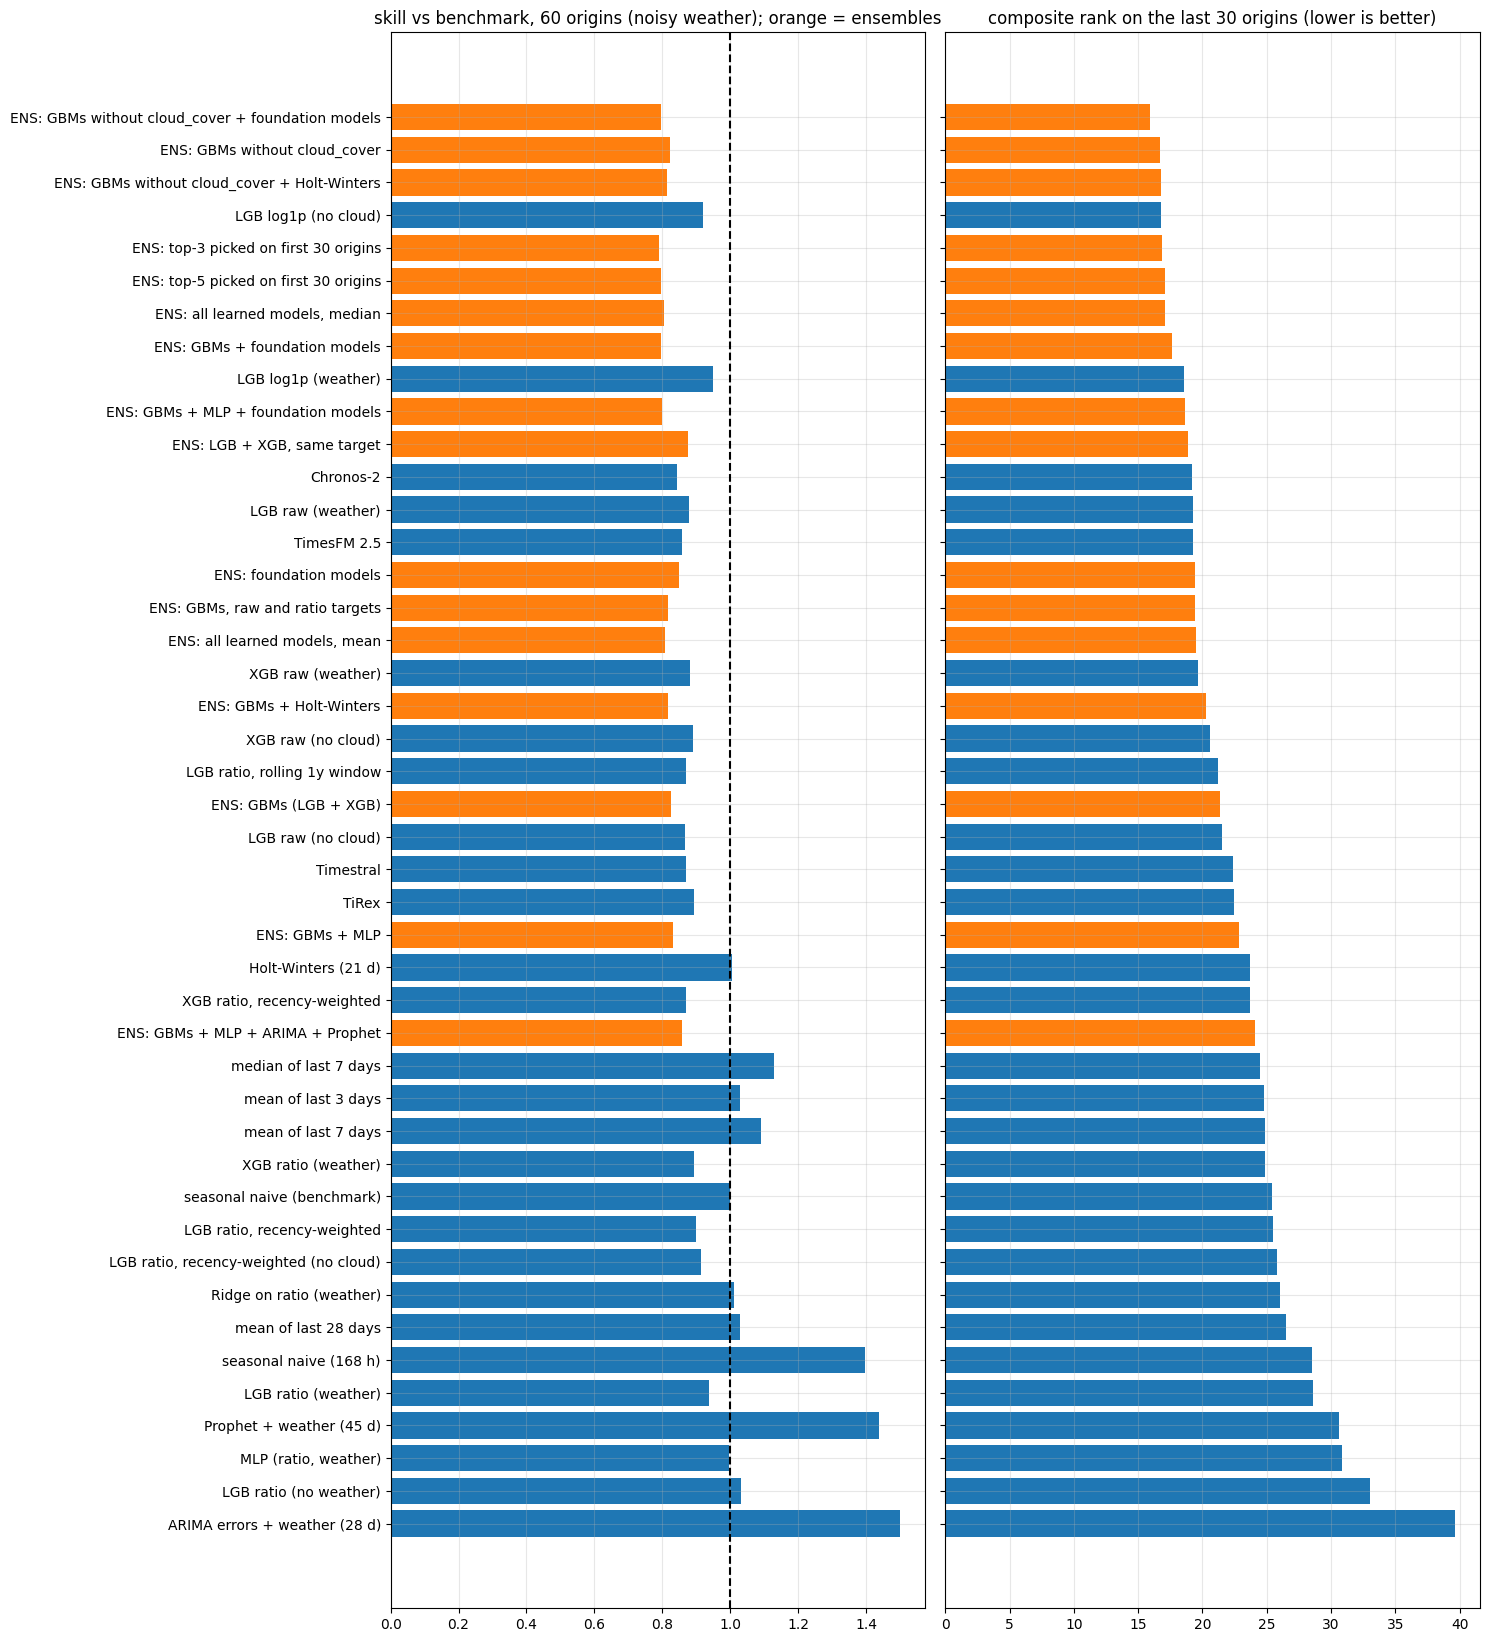

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 0.33 * len(board_noisy) + 2))
b = board_noisy
colors = ["tab:orange" if nm.startswith("ENS") else "tab:blue" for nm in b.index]
axes[0].barh(b.index, b["skill (60)"], color=colors); axes[0].axvline(1, color="k", ls="--")
axes[0].set_title("skill vs benchmark, 60 origins (noisy weather); orange = ensembles"); axes[0].invert_yaxis()
axes[1].barh(b.index, b["composite rank"], color=colors)
axes[1].set_title("composite rank on the last 30 origins (lower is better)"); axes[1].invert_yaxis()
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

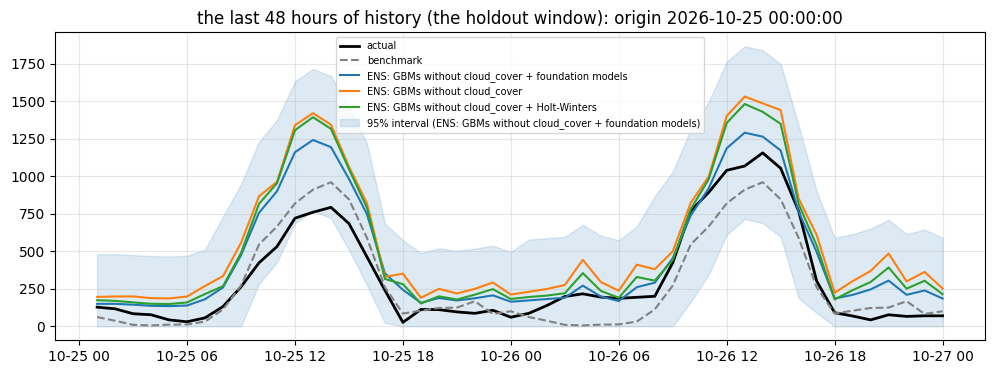

In [21]:
# The three best by composite rank, drawn on the latest origin, with the additive 95% interval of the first
top3 = [nm for nm in board_noisy.index if nm != BENCH][:3]
o = NVAL - 1
t = ds.iloc[VAL[o] + K].to_numpy()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t, actual[o], color="black", lw=2, label="actual")
ax.plot(t, preds["noisy"][BENCH][o], color="gray", ls="--", label="benchmark")
for i, nm in enumerate(top3):
    ax.plot(t, preds["noisy"][nm][o], label=nm)
lo, hi = interval_eval(preds["noisy"][top3[0]], cal, ev)["additive"]
ax.fill_between(t, lo[o], hi[o], color="C0", alpha=0.15, label=f"95% interval ({top3[0]})")
ax.legend(fontsize=7); ax.set_title(f"the last 48 hours of history (the holdout window): origin {ds.iloc[VAL[o]]}")
plt.show()

### Interval recipes for the three best

The additive recipe is the one used in the table above. Here it is next to the two relative ones, on the last
30 origins (noisy weather), with the benchmark's own interval for reference.

In [22]:
def eval_rows(name, lo, hi):
    inside = (actual[ev] >= lo[ev]) & (actual[ev] <= hi[ev])
    return {"model / recipe": name, "coverage %": 100 * inside.mean(),
            "Winkler": np.mean([winkler(actual[o], lo[o], hi[o]) for o in ev]),
            "Winkler day 2": np.mean([winkler(actual[o, 24:], lo[o, 24:], hi[o, 24:]) for o in ev]),
            "mean width": (hi[ev] - lo[ev]).mean()}


rows = [eval_rows("seasonal naive / standard", BENCH_LO, BENCH_HI)]
for nm in top3:
    for recipe, (lo, hi) in interval_eval(preds["noisy"][nm], cal, ev).items():
        rows.append(eval_rows(f"{nm} / {recipe}", lo, hi))
display(pd.DataFrame(rows).set_index("model / recipe").round(1))

,coverage %,Winkler,Winkler day 2,mean width
model / recipe,,,,
seasonal naive / standard,74.2,3029.6,3076.0,662.3
ENS: GBMs without cloud_cover + foundation models / additive,90.2,1310.0,1473.0,804.2
ENS: GBMs without cloud_cover + foundation models / relative,84.3,1507.7,1556.7,713.7
"ENS: GBMs without cloud_cover + foundation models / relative, asymmetric",79.4,1956.5,2212.4,683.1
ENS: GBMs without cloud_cover / additive,91.4,1281.6,1380.9,851.6
ENS: GBMs without cloud_cover / relative,86.2,1517.8,1541.5,774.0
"ENS: GBMs without cloud_cover / relative, asymmetric",73.7,2097.1,2358.9,695.8
ENS: GBMs without cloud_cover + Holt-Winters / additive,90.3,1298.7,1443.6,836.0
ENS: GBMs without cloud_cover + Holt-Winters / relative,85.8,1531.9,1587.7,750.0


## 5. Open questions for the next step

- Which model (or ensemble) goes into the final fit, and is its lead over the benchmark more than noise? Look at `beats benchmark %` and at how the holdout and the 60-origin skills agree.
- The interval: the additive recipe, or something better? Does it hold on day 2?
- The foundation models do not see the weather. If they are close to the benchmark, are they still useful inside an ensemble?

## 6. Add-ons (run these after section 5, in order; they only use what is already in memory)

- 6.1 shrink the model towards the benchmark, and skill on the most recent origins
- 7 a better interval (online calibration, a width multiplier)
- 8 is the lead over the benchmark more than noise? (block bootstrap)
- 9 Chronos-2 with the future weather as covariates (optional, needs the foundation models)
- 10 sanity check: what did past days with similar weather do?
- 11 fit every model on all the history, forecast the 48 hours, and a `make_submission` function (nothing is saved until you call it)

In [ ]:
# ---- 6.0 shared helpers for the add-on sections ------------------------------------------------------------------
P_ = preds["noisy"]                                                   # backtest forecasts with the noisy weather
FINAL_CAND = next(c for c in ("ENS: GBMs without cloud_cover + foundation models", "ENS: GBMs without cloud_cover") if c in P_)
tpos = VAL[:, None] + K[None, :]


def R(nm):                                                            # RMSE per origin, shape (NVAL,)
    return np.sqrt(((actual - preds["noisy"][nm]) ** 2).mean(1))


def group_ids(daylight, kind="4"):
    # "4": night/day x day 1/day 2.  "12": blocks of 4 hours of the horizon x day 1/day 2.
    dl = np.asarray(daylight).astype(int)
    day2 = np.broadcast_to((K - 1) // 24, dl.shape)
    if kind == "4":
        return dl * 2 + day2
    return np.broadcast_to(((K - 1) % 24) // 4, dl.shape) + 6 * day2


print("main candidate for the add-ons:", FINAL_CAND)

### 6.1 Shrinking towards the benchmark, and the most recent origins

`w * model + (1 - w) * seasonal naive`. If the model is better than the benchmark on average but noisy, a partial
blend can win more often. `beats %` is the share of origins on which the blend has a lower RMSE than the benchmark,
which is the thing the Session 1 points depend on (one window only). The "last 15 / last 10" columns look at the most
recent days only, because the level has been falling since mid-October (a regime change).

In [ ]:
rb_ = R(BENCH)
sk = lambda r, idx: r[idx].mean() / rb_[idx].mean()
lastk = lambda k: np.arange(NVAL - k, NVAL)

rows = []
for w in np.round(np.arange(0, 1.01, 0.1), 1):
    r = np.sqrt(((actual - (w * P_[FINAL_CAND] + (1 - w) * P_[BENCH])) ** 2).mean(1))
    rows.append({"w (model share)": w, "skill (60)": sk(r, np.arange(NVAL)), "skill (first 30)": sk(r, cal),
                 "skill (last 30)": sk(r, ev), "skill (last 15)": sk(r, lastk(15)), "skill (last 10)": sk(r, lastk(10)),
                 "beats % (60)": 100 * (r < rb_).mean(), "beats % (last 15)": 100 * (r[lastk(15)] < rb_[lastk(15)]).mean(),
                 "holdout skill": r[-1] / rb_[-1]})
print(f"blend of {FINAL_CAND} with the benchmark (noisy weather)")
display(pd.DataFrame(rows).set_index("w (model share)").round(3))

CAND = [nm for nm in board_noisy.index if nm != BENCH][:8]
if FINAL_CAND not in CAND:
    CAND.append(FINAL_CAND)
rec = pd.DataFrame({nm: {"skill (60)": sk(R(nm), np.arange(NVAL)), "skill (last 30)": sk(R(nm), ev),
                         "skill (last 15)": sk(R(nm), lastk(15)), "skill (last 10)": sk(R(nm), lastk(10)),
                         "beats % (last 15)": 100 * (R(nm)[lastk(15)] < rb_[lastk(15)]).mean(),
                         "holdout skill": R(nm)[-1] / rb_[-1]} for nm in CAND}).T
print("the best candidates, on recent origins")
display(rec.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
rr = R(FINAL_CAND) / rb_
axes[0].bar(range(NVAL), rr, color=np.where(rr < 1, "tab:green", "tab:red")); axes[0].axhline(1, color="k", ls="--")
axes[0].set_title(f"RMSE ratio to the benchmark, each origin (green = better)\n{FINAL_CAND}", fontsize=9)
axes[0].set_xlabel("origin (0 = oldest of the 60, 59 = the last 48 hours)")
err_m = (actual - P_[FINAL_CAND])[lastk(15)].mean(0)
err_b = (actual - P_[BENCH])[lastk(15)].mean(0)
axes[1].plot(K, err_m, label=FINAL_CAND[:40]); axes[1].plot(K, err_b, color="gray", ls="--", label="benchmark")
axes[1].axhline(0, color="k", lw=0.8); axes[1].legend(fontsize=7)
axes[1].set_title("mean error (actual - forecast) by horizon, last 15 origins: below 0 = forecasts too high", fontsize=9)
plt.tight_layout(); plt.show()

## 7. A better interval

The table so far calibrated the width on the first 30 origins and judged it on the last 30, which gave about 90%
coverage instead of 95%, because recent errors are larger. Here the band is calibrated **online**: for origin `j` it uses
the 95th percentile of |error| of the previous (up to 40) origins that were fully known at that time (`j-2` and earlier),
times a multiplier `s`. Two groupings: `4` (night/day x day 1/day 2) and `12` (4-hour blocks of the horizon x day 1/day 2).
The private leaderboard scores the **last 24 hours**, so the best `s` is read from `Winkler day 2`.

In [ ]:
J = np.arange(22, NVAL)                                   # origins that have at least 20 earlier origins to calibrate on


def online_band(p, kind="4", s=1.0, back=40, q=0.95):
    G = group_ids(W["daylight"][tpos], kind)
    ae = np.abs(actual - p)
    lo, hi = np.full((NVAL, H), np.nan), np.full((NVAL, H), np.nan)
    for j in J:
        past = np.arange(max(0, j - back), j - 1)
        pooled = np.quantile(ae[past], q)
        qk = np.array([np.quantile(ae[past][G[past] == k], q) if (G[past] == k).sum() >= 15 else pooled
                       for k in range(G.max() + 1)])
        half = s * qk[G[j]]
        lo[j], hi[j] = np.clip(p[j] - half, 0, None), p[j] + half
    return lo, hi


def band_stats(lo, hi, idx=J):
    ins = (actual[idx] >= lo[idx]) & (actual[idx] <= hi[idx])
    return {"coverage %": 100 * ins.mean(), "coverage % day 2": 100 * ins[:, 24:].mean(),
            "Winkler": np.mean([winkler(actual[o], lo[o], hi[o]) for o in idx]),
            "Winkler day 2": np.mean([winkler(actual[o, 24:], lo[o, 24:], hi[o, 24:]) for o in idx]),
            "mean width": (hi[idx] - lo[idx]).mean()}


rows = {"seasonal naive / its own interval": band_stats(BENCH_LO, BENCH_HI)}
for kind in ("4", "12"):
    for s in np.round(np.arange(0.8, 1.61, 0.1), 1):
        rows[f"{kind} groups, s={s}"] = band_stats(*online_band(P_[FINAL_CAND], kind, s))
tab = pd.DataFrame(rows).T
display(tab.sort_values("Winkler day 2").head(12).round(1))
best = tab.drop(index="seasonal naive / its own interval")["Winkler day 2"].idxmin()
INT_KIND, INT_S = best.split(" groups, s=")[0], float(best.split("s=")[1])
print(f"best by Winkler on day 2: kind={INT_KIND}, s={INT_S}   (s=1.0 and 4 groups is the plain version: "
      f"Winkler day 2 = {tab.loc['4 groups, s=1.0', 'Winkler day 2']:.0f}, coverage {tab.loc['4 groups, s=1.0', 'coverage %']:.0f}%)")
print("the best s is picked on the same 38 origins that it is judged on, so treat the gain as optimistic; prefer a round s close to it.")

## 8. Is the lead more than noise?

Paired moving-block bootstrap (blocks of 5 origins, because neighbouring origins overlap) of the ratio
`mean RMSE of A / mean RMSE of B` over the 60 origins. The 5%-95% interval shows how much the ratio could move by chance,
and `P(A better)` is the share of resamples with a ratio below 1.

In [ ]:
def block_boot(a, b, block=5, B=4000, seed=1):
    rng_b = np.random.default_rng(seed)
    N = len(a)
    nb = int(np.ceil(N / block))
    out = np.empty(B)
    for i in range(B):
        st = rng_b.integers(0, N - block + 1, nb)
        ix = (st[:, None] + np.arange(block)[None, :]).ravel()[:N]
        out[i] = a[ix].mean() / b[ix].mean()
    return np.median(out), np.quantile(out, 0.05), np.quantile(out, 0.95), (out < 1).mean()


others = [BENCH, "ENS: GBMs without cloud_cover", "ENS: all learned models, median", "ENS: top-3 picked on first 30 origins",
          "ENS: GBMs + foundation models", "ENS: foundation models", "Chronos-2", "LGB log1p (no cloud)",
          "ENS: GBMs (LGB + XGB)", "LGB raw (no cloud)"]
rows = []
for nm in others:
    if nm in preds["noisy"] and nm != FINAL_CAND:
        m_, lo_, hi_, pb = block_boot(R(FINAL_CAND), R(nm))
        rows.append({"A = main candidate vs B": nm, "ratio A/B (median)": m_, "5%": lo_, "95%": hi_, "P(A better)": pb})
display(pd.DataFrame(rows).set_index("A = main candidate vs B").round(3))
print("main candidate A =", FINAL_CAND)
print("a row whose 5%-95% range contains 1 means A and B cannot be told apart with 60 origins: prefer the simpler / more robust one.")

## 9. Chronos-2 with the future weather (optional)

Chronos-2 accepts covariates: the past weather next to the target, and the forecast weather for the 48 hours ahead.
Here it gets temperature, wind speed, pressure, humidity and daylight (never `cloud_cover`). It runs on exactly the
same 60 origins and the same noisy weather as the other models, then joins the tournament and two new ensembles are
added. If anything fails the cell prints the reason and the rest of the notebook is unaffected.

In [ ]:
CHR_MODELS = []
COVS = ["temperature", "wind_speed", "pressure", "humidity", "daylight"]


class ChronosCov:
    def __init__(self, pipe, name, ctx=512):
        self.pipe, self.name, self.ctx = pipe, name, ctx
    def fit(self, i0): pass
    def predict(self, orig, wx):
        out = []
        for j, o in enumerate(orig):
            sl = slice(o - self.ctx + 1, o + 1)
            inp = {"target": np.asarray(y[sl], dtype=np.float32),
                   "past_covariates": {c: np.asarray(W[c][sl], dtype=np.float32) for c in COVS},
                   "future_covariates": {c: np.asarray(wx[c][j], dtype=np.float32) for c in COVS}}
            q, _ = self.pipe.predict_quantiles([inp], prediction_length=H, quantile_levels=[0.1, 0.5, 0.9])
            out.append(np.clip(np.asarray(q[0]).reshape(-1, H, 3)[0][:, 1], 0, None))
        return np.array(out)


def run_chronos_cov():
    import torch
    from chronos import BaseChronosPipeline
    pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map="cuda" if torch.cuda.is_available() else "cpu")
    models = [ChronosCov(pipe, "Chronos-2 + weather (512 h)", 512), ChronosCov(pipe, "Chronos-2 + weather (1024 h)", 1024)]
    test = models[0].predict(np.array([VAL[0]]), hist_wx(np.array([VAL[0]])))
    assert test.shape == (1, H) and np.isfinite(test).all()
    rng2 = np.random.default_rng(0)                         # the same noisy weather as in the tournament
    new = {m.name: {mode: np.full((NVAL, H), np.nan) for mode in preds} for m in models}
    t0 = time.time()
    for b in range(0, NVAL, BLOCK):
        idx = VAL[b:b + BLOCK]
        wx_a = hist_wx(idx)
        wx_n = perturb(wx_a, rng2)
        for m in models:
            new[m.name]["actual"][b:b + BLOCK] = m.predict(idx, wx_a)
            new[m.name]["noisy"][b:b + BLOCK] = m.predict(idx, wx_n)
    print(f"done in {time.time() - t0:.0f}s")
    return models, new


if globals().get("RUN_FOUNDATION", False):
    try:
        CHR_MODELS, new_preds = run_chronos_cov()
        for nm, d in new_preds.items():
            for mode in preds:
                preds[mode][nm] = d[mode]
            SAFE.add(nm)
        names_new = [m.name for m in CHR_MODELS]
        add_ens("ENS: GBMs without cloud_cover + foundation models + Chronos-2 weather", NOCLOUD + FMN + names_new)
        add_ens("ENS: GBMs without cloud_cover + Chronos-2 weather", NOCLOUD + names_new)
        board_noisy, board_actual = leaderboard("noisy"), leaderboard("actual")
        show = names_new + [n_ for n_ in ENS if "Chronos-2 weather" in n_]
        print("new rows (noisy weather); the full tables are rebuilt in board_noisy / board_actual")
        display(board_noisy.loc[show].round(3))
        print("for reference, the current top 5 by composite rank:")
        display(board_noisy.head(5).round(3))
    except Exception as e:
        print("Chronos-2 with covariates skipped:", type(e).__name__, str(e)[:300])
else:
    print("RUN_FOUNDATION is off: skipped")

## 10. Sanity check: what did similar days do?

Uses only `train.csv`. For each of the two forecast days (hours 1 to 24 and 25 to 48) it finds the 10 past days, in the
same part of the year (within 45 days of the same day number, any year), whose **weather** is most alike
(humidity, temperature, daily temperature range, wind, pressure; not cloud_cover, because of its coding problem).
Each analog day's output is expressed relative to the mean daily output of the 7 days before it, which removes the capacity growth.
The result is a rough reference: `check_forecast(fc)` (used in section 11) compares a model's day totals with it.

In [ ]:
mids = np.where(hour == 0)[0]
mids = mids[(mids >= 24 * 9) & (mids + 24 <= n - 1)]
doy_ = ds.dt.dayofyear.to_numpy()
recs = []
for m in mids:
    sl = slice(m + 1, m + 25)
    prev = np.mean([y[m + 1 - 24 * k: m + 25 - 24 * k].sum() for k in range(1, 8)])
    recs.append({"date": ds.iloc[m].date(), "doy": doy_[m], "humidity": W["humidity"][sl].mean(), "temp": W["temperature"][sl].mean(),
                 "temp range": np.ptp(W["temperature"][sl]), "wind": W["wind_speed"][sl].mean(), "pressure": W["pressure"][sl].mean(),
                 "total": y[sl].sum(), "rel to prev 7 days": y[sl].sum() / prev})
A = pd.DataFrame(recs)
FEAT = ["humidity", "temp", "temp range", "wind", "pressure"]
LEVEL_REF = np.mean([y[n - 24 * k: n + 24 - 24 * k].sum() for k in range(1, 8)])          # mean daily total of the last 7 days
BENCH_DAYS = [y[n - 24: n].sum(), y[n - 24: n].sum()]                                      # the benchmark repeats yesterday
print(f"mean daily total of the last 7 days: {LEVEL_REF:.0f}   |   yesterday (what the benchmark repeats): {y[n - 24: n].sum():.0f}")

ANALOG = {}
for d, name_ in enumerate(("day 1 (hours 1-24)", "day 2 (hours 25-48)")):
    sl = slice(24 * d, 24 * d + 24)
    f = {"humidity": wfc["humidity"].iloc[sl].mean(), "temp": wfc["temperature"].iloc[sl].mean(),
         "temp range": np.ptp(wfc["temperature"].iloc[sl]), "wind": wfc["wind_speed"].iloc[sl].mean(), "pressure": wfc["pressure"].iloc[sl].mean()}
    f_doy = wfc["ds"].iloc[24 * d + 12].dayofyear
    dd = np.abs(A["doy"] - f_doy)
    pool = A[np.minimum(dd, 365 - dd) <= 45].copy()
    z = (pool[FEAT] - pool[FEAT].mean()) / pool[FEAT].std()
    zf = (pd.Series(f)[FEAT] - pool[FEAT].mean()) / pool[FEAT].std()
    pool["distance"] = np.sqrt(((z - zf) ** 2).sum(1))
    top = pool.sort_values("distance").head(10)
    rel = top["rel to prev 7 days"]
    ANALOG[d] = {"median": rel.median() * LEVEL_REF, "q25": rel.quantile(0.25) * LEVEL_REF, "q75": rel.quantile(0.75) * LEVEL_REF}
    print(f"\n{name_}: forecast weather {({k: round(float(v), 1) for k, v in f.items()})}")
    display(top[["date", "humidity", "temp", "temp range", "wind", "pressure", "total", "rel to prev 7 days", "distance"]].round(2))
    print(f"analogs say: total about {ANALOG[d]['median']:.0f}  (middle half {ANALOG[d]['q25']:.0f} to {ANALOG[d]['q75']:.0f})")


def check_forecast(fc, label=""):
    fc = np.asarray(fc, float)
    for d in (0, 1):
        tot = fc[24 * d: 24 * d + 24].sum()
        a = ANALOG[d]
        flag = "inside" if a["q25"] <= tot <= a["q75"] else ("ABOVE" if tot > a["q75"] else "BELOW")
        print(f"{label} day {d + 1}: forecast total {tot:8.0f} | analogs {a['q25']:.0f} to {a['q75']:.0f} (median {a['median']:.0f}) -> {flag} | benchmark {BENCH_DAYS[d]:.0f}")

## 11. Fit everything on all the history and forecast the 48 hours

Every model is refitted on **all** of `train.csv` and forecasts the 48 hours in `weather_forecast.csv` (the real forecast
weather, no simulated noise). The ensembles are the same combinations as in section 3. Nothing is written to disk here.
Look at the table, choose a model (and `w`, `s`), then call `make_submission(...)` in the last cell.

In [ ]:
wx_final = {c: wfc[c].to_numpy(float)[None, :] for c in WX}
O_FINAL = np.array([n - 1])                                  # the last row of train.csv is 00:00, the origin of the forecast
FINAL_FC, final_fail = {}, {}
t0 = time.time()
for m in list(MODELS) + list(CHR_MODELS):
    try:
        m.fit(n - 1)
        FINAL_FC[m.name] = m.predict(O_FINAL, wx_final)[0]
    except Exception as e:
        final_fail[m.name] = f"{type(e).__name__}: {str(e)[:100]}"
for label, members in ENS.items():
    if all(mm in FINAL_FC for mm in members):
        A_ = np.stack([FINAL_FC[mm] for mm in members])
        FINAL_FC[label] = np.median(A_, 0) if "median" in label else A_.mean(0)
print(f"{len(FINAL_FC)} forecasts in {time.time() - t0:.0f}s", f"| failed: {final_fail}" if final_fail else "| none failed")

tab = pd.DataFrame({nm: {"day 1 total": f[:24].sum(), "day 2 total": f[24:].sum(), "peak hour": f.max(),
                         "skill (last 30)": sk(R(nm), ev) if nm in preds["noisy"] else np.nan,
                         "composite rank": board_noisy["composite rank"].get(nm, np.nan),
                         "uses cloud_cover": board_noisy["uses cloud_cover"].get(nm, "")} for nm, f in FINAL_FC.items()}).T
tab = tab.sort_values("composite rank")
display(tab.round(1))
print("benchmark totals: day 1", round(BENCH_DAYS[0]), "| day 2", round(BENCH_DAYS[1]), "(it repeats yesterday)")
check_forecast(FINAL_FC[FINAL_CAND], label=FINAL_CAND[:45])

fig, ax = plt.subplots(figsize=(13, 4))
hist_t = ds.iloc[-24 * 5:]; ax.plot(hist_t, y[-24 * 5:], color="black", label="last 5 days (actual)")
tf = wfc["ds"]
ax.plot(tf, FINAL_FC[BENCH], color="gray", ls="--", label="benchmark")
for nm in dict.fromkeys([FINAL_CAND, "ENS: GBMs without cloud_cover", "ENS: foundation models", "ENS: all learned models, median"]):
    if nm in FINAL_FC:
        ax.plot(tf, FINAL_FC[nm], label=nm[:55])
ax.legend(fontsize=7); ax.set_title("the 48-hour forecasts of the main candidates"); plt.show()

In [ ]:
SURNAME = "Boichuk"            # check the file name the template asks for: SURNAME_project.csv


def make_submission(name, w=1.0, s=1.0, kind="4", back=None, save=False):
    """Point forecast = w * model + (1 - w) * seasonal naive.
    Band = forecast +- s * (95th percentile of |error| of the same blend over the backtest origins, by group)."""
    fc = w * FINAL_FC[name] + (1 - w) * FINAL_FC[BENCH]
    Pb = w * preds["noisy"][name] + (1 - w) * preds["noisy"][BENCH]
    ae = np.abs(actual - Pb)
    use = np.arange(NVAL) if back is None else np.arange(NVAL - back, NVAL)
    G = group_ids(W["daylight"][tpos], kind)[use]
    gF = group_ids(wfc["daylight"].to_numpy(), kind)
    pooled = np.quantile(ae[use], 0.95)
    qk = np.array([np.quantile(ae[use][G == k], 0.95) if (G == k).sum() >= 15 else pooled for k in range(G.max() + 1)])
    half = s * qk[gF]
    fc = np.clip(fc, 0, None)
    out = pd.DataFrame({"ds": wfc["ds"].dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": fc,
                        "lower_95": np.clip(fc - half, 0, None), "upper_95": fc + half})
    assert len(out) == 48 and out.notna().all().all()
    assert (out["lower_95"] >= 0).all() and (out["lower_95"] <= out["forecast"]).all() and (out["forecast"] <= out["upper_95"]).all()
    print(f"{name}: w={w}, s={s}, groups={kind} | mean width {np.mean(out['upper_95'] - out['lower_95']):.0f} | "
          f"day totals {fc[:24].sum():.0f} / {fc[24:].sum():.0f}")
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(ds.iloc[-24 * 5:], y[-24 * 5:], color="black")
    ax.plot(wfc["ds"], out["forecast"], color="C0"); ax.fill_between(wfc["ds"], out["lower_95"], out["upper_95"], color="C0", alpha=0.2)
    ax.set_title("submission preview"); plt.show()
    if save:
        fn = f"{SURNAME}_project.csv"
        out.to_csv(fn, index=False)
        print("saved", fn)
        try:
            from google.colab import files
            files.download(fn)
        except ImportError:
            pass
    return out


# Example (do not run until we have chosen):
# sub = make_submission(FINAL_CAND, w=1.0, s=INT_S, kind=INT_KIND, save=False)